In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math


In [2]:
df=pd.read_csv(r"C:\\Users\\USER\\Downloads\\classification\\hotel_bookings_updated_2024.csv")
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,city
0,Resort Hotel - Chandigarh,0,342,2024,July,30,27,0,0,2,...,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2024-07-27 22:16:40.916332324,Chandigarh
1,Resort Hotel - Mumbai,0,737,2024,April,17,28,0,0,2,...,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2024-04-28 21:56:21.507509066,Mumbai
2,Resort Hotel - Delhi,0,7,2024,September,37,10,0,1,1,...,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2024-09-10 03:46:25.734029096,Delhi
3,Resort Hotel - Kolkata,0,13,2024,August,33,14,0,1,1,...,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2024-08-14 18:07:10.049669568,Kolkata
4,Resort Hotel - Lucknow,0,14,2024,September,37,14,0,2,2,...,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2024-09-14 14:27:32.473846000,Lucknow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel - Pune,0,23,2024,September,39,29,2,5,2,...,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2024-09-29 05:33:06.002060492,Pune
119386,City Hotel - Mumbai,0,102,2024,November,46,16,2,5,3,...,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2024-11-16 01:55:18.426320680,Mumbai
119387,City Hotel - Lucknow,0,34,2024,April,16,19,2,5,2,...,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2024-04-19 07:50:22.982016768,Lucknow
119388,City Hotel - Ahmedabad,0,109,2024,October,40,5,2,5,2,...,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2024-10-05 12:37:40.429352788,Ahmedabad


In [3]:
df.shape

(119390, 33)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [5]:
df.isnull().sum() # missing values

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [6]:

df['children']=df['children'].fillna(df['children'].median())# numerical data,mode--->categorical data
df['country']=df['country'].fillna(df['country'].mode()[0])  # fill the missing values

In [7]:
df.drop(columns=['company'],inplace=True)
df.drop(columns=['agent'],inplace=True)

In [8]:

df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [9]:
df.duplicated().sum() # duplicate values

np.int64(0)

In [10]:
df["reservation_status"].value_counts()

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

### Handling outliers


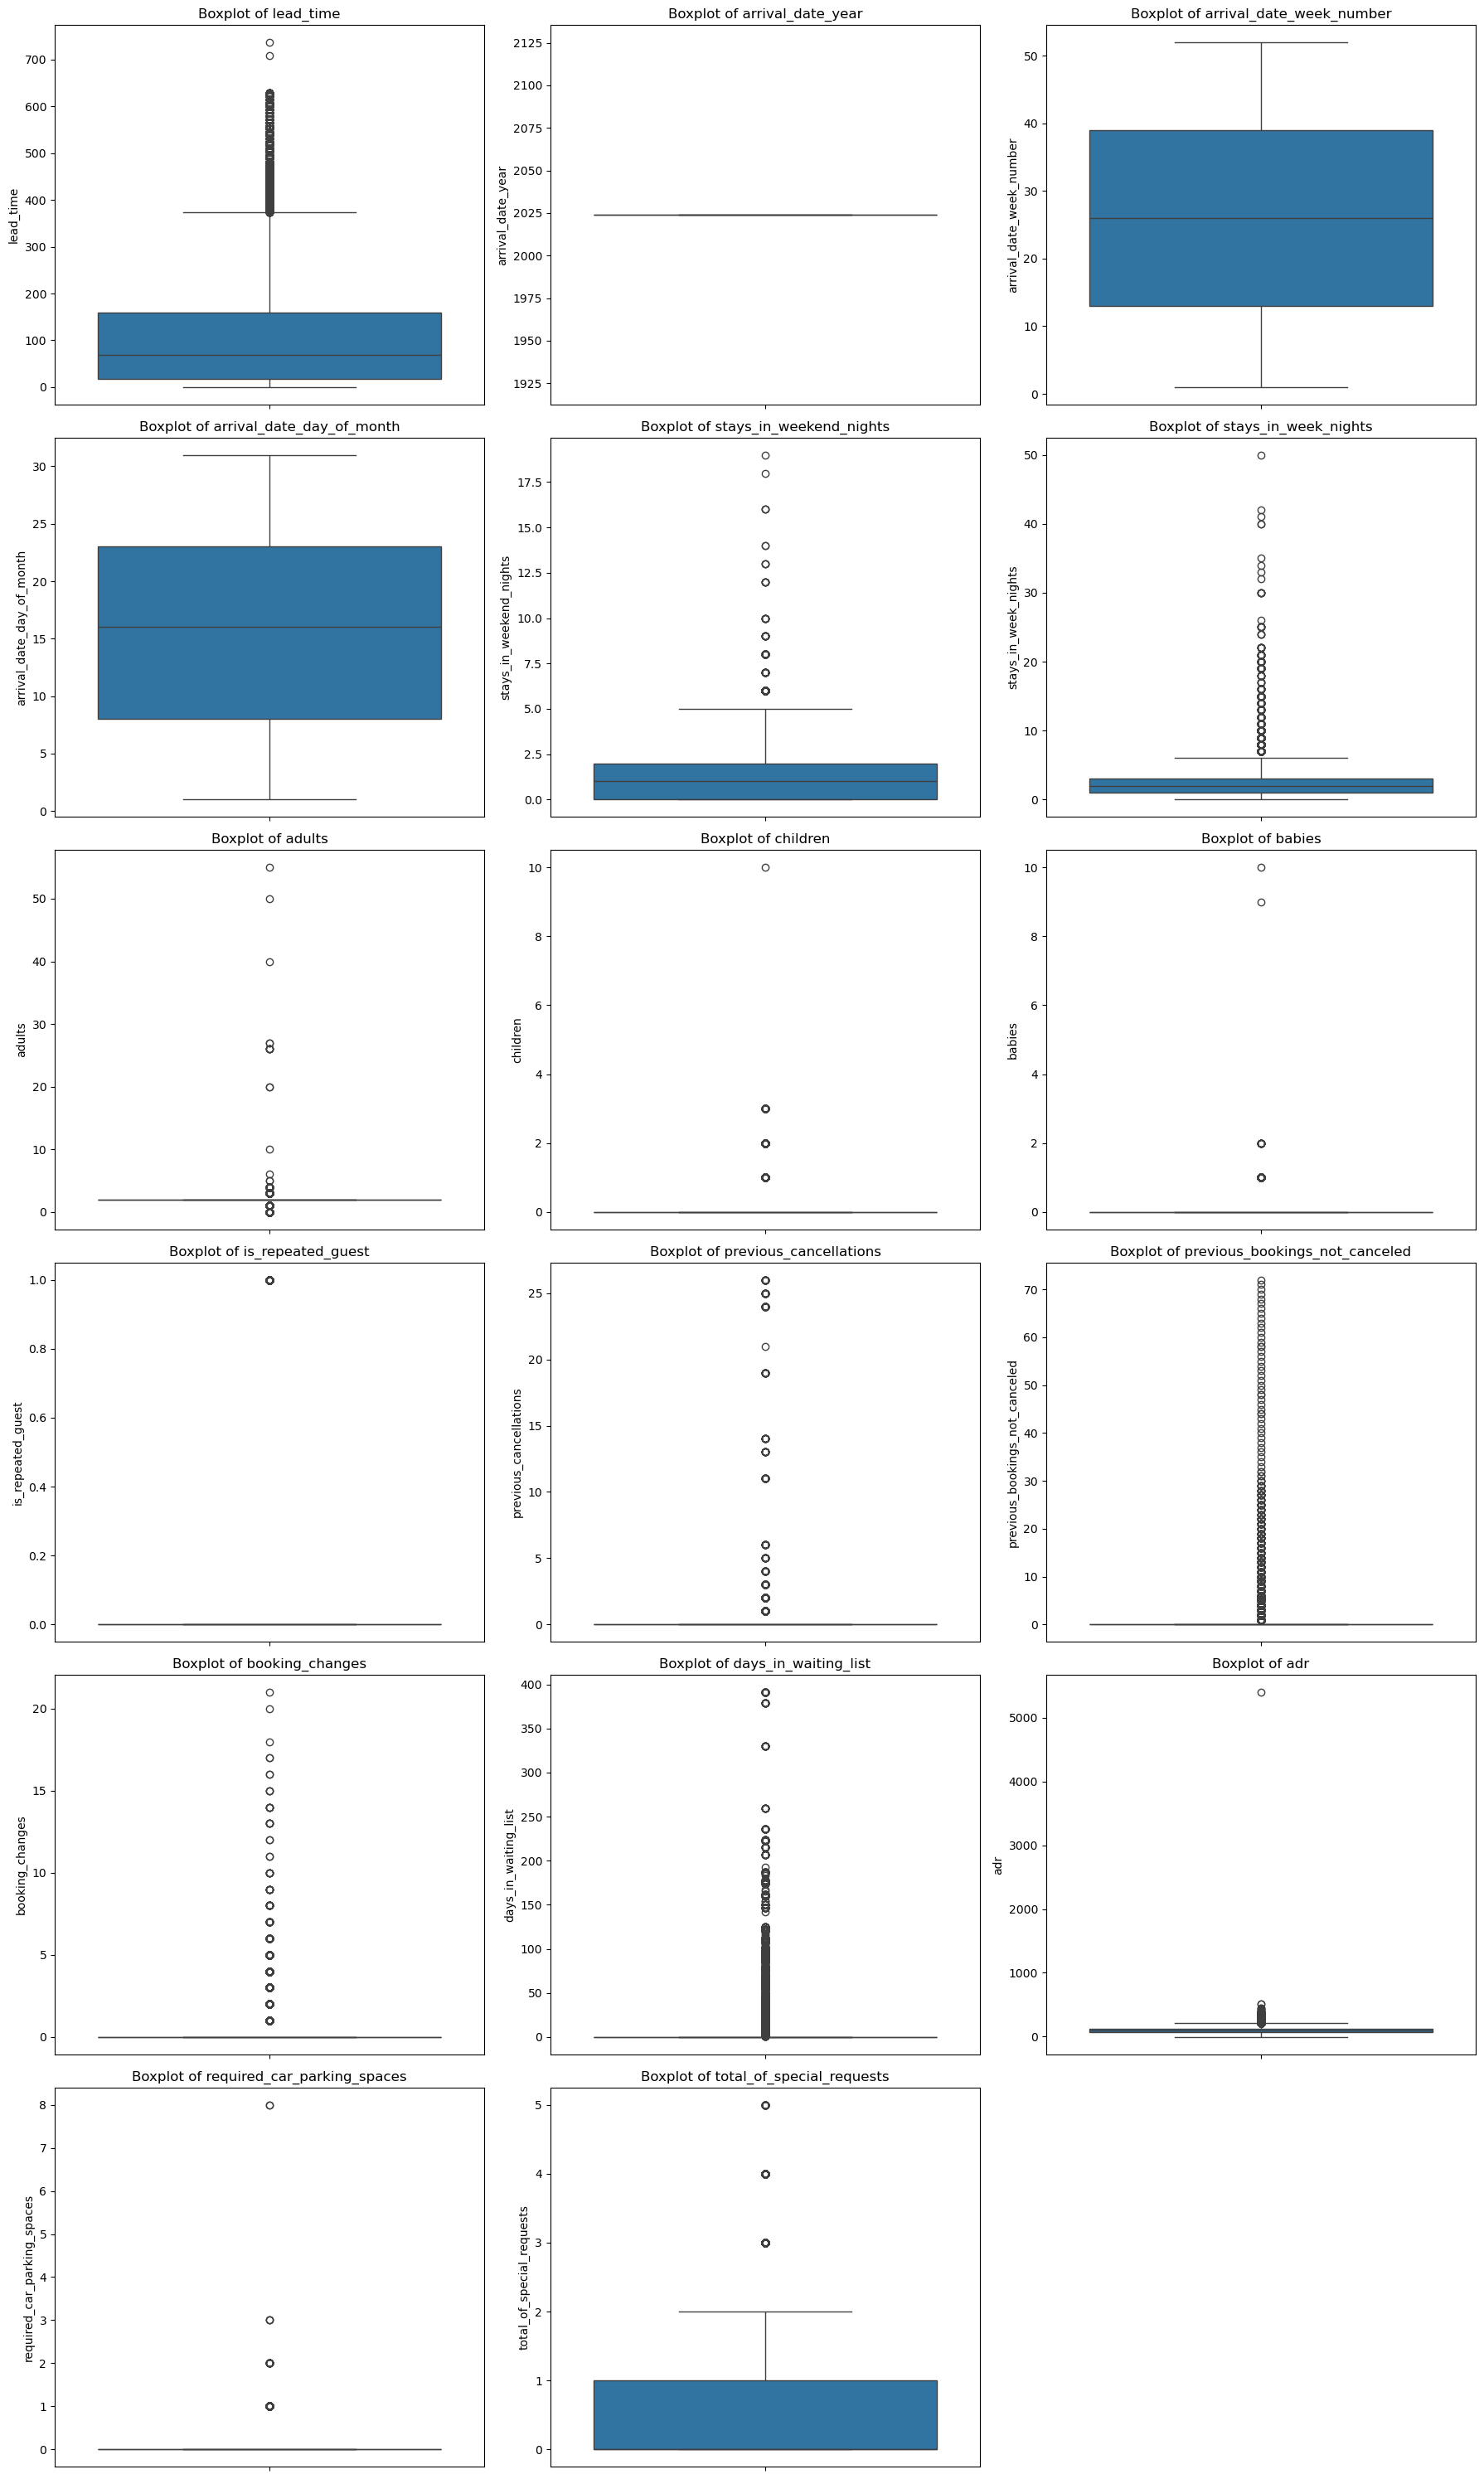

In [11]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Select numerical columns
num_cols = df.select_dtypes(include="number").columns.tolist()

# Exclude target and identifier columns from outlier analysis
exclude_cols = ["is_canceled", "agent", "company"]
features = [col for col in num_cols if col not in exclude_cols]

# Create multiple rows of boxplots
n_cols = 3
n_rows = math.ceil(len(features) / n_cols)

plt.figure(figsize=(18, 5 * n_rows))

for i, feature in enumerate(features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[feature])
    plt.title(f"Boxplot of {feature}")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

### Remove outliers

In [12]:
# 1. Select numerical columns
num_cols = df.select_dtypes(include="number").columns

# 2. Exclude target and identifier columns
exclude_cols = ["is_canceled", "agent", "company"]
features = [col for col in num_cols if col not in exclude_cols]

# 3. Calculate IQR limits and remove outlier rows
for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

# 4. Check final dataset shape
print("Dataset shape after removing outliers:", df.shape)

Dataset shape after removing outliers: (119390, 31)


In [15]:
leakage_columns = [
    "is_canceled",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list"
]

df1 = df.drop(columns=leakage_columns, errors="ignore")

print(df1.shape)
print(df1.columns.tolist())

(119390, 26)
['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'city']


### splitting the data

In [16]:
# Independent variables
X = df.drop("reservation_status", axis=1)

# Dependent variable
y = df["reservation_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (119390, 25)
y shape: (119390,)


In [17]:
print(y.value_counts())
print("\nPercentage:")
print(y.value_counts(normalize=True) * 100)

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

Percentage:
reservation_status
Check-Out    62.958372
Canceled     36.030656
No-Show       1.010972
Name: proportion, dtype: float64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (95512, 25)
Testing data: (23878, 25)


### numerical and categorical data

In [19]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import accuracy_score, classification_report

In [20]:
num_cols = X_train.select_dtypes(include=['number']).columns

cat_cols = X_train.select_dtypes(include=['object', 'category']).columns

print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))
print("Numerical columns:",num_cols)
print("Categorical columns:",cat_cols)

Numerical: 15
Categorical: 10
Numerical columns: Index(['lead_time', 'arrival_date_year', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='object')
Categorical columns: Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'deposit_type',
       'customer_type', 'city'],
      dtype='object')


### Pipeline

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=100
    ))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [22]:
num_pipeline

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [23]:
cat_pipeline

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [24]:
preprocessor 

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### PCA

In [25]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (95512, 141)
Testing shape: (23878, 141)


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)
print("Training data shape:", X_train_scaled.shape)
print("Number of columns:", X_train_scaled.shape[1])

Training data shape: (95512, 141)
Number of columns: 141


In [28]:
from sklearn.decomposition import PCA

# Apply PCA
pca = PCA(
    n_components=100,
    svd_solver='arpack',
    random_state=42
)

# Fit PCA on training data
X_train_pca = pca.fit_transform(X_train_processed)

# Transform testing data
X_test_pca = pca.transform(X_test_processed)

# Display results
print("Training shape:", X_train_pca.shape)
print("Testing shape:", X_test_pca.shape)

print("Explained variance:",
      pca.explained_variance_ratio_.sum())

Training shape: (95512, 100)
Testing shape: (23878, 100)
Explained variance: 0.9992797768644688


### Filter Method

In [29]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=50)

X_train_selected = selector.fit_transform(
    X_train_processed, y_train
)

X_test_selected = selector.transform(
    X_test_processed
)
print("Before:", X_train_processed.shape)
print("After:", X_train_selected.shape)
print("Before Filter Method:", X_train_processed.shape[1])
print("After Filter Method:", X_train_selected.shape[1])

Before: (95512, 141)
After: (95512, 50)
Before Filter Method: 141
After Filter Method: 50


c:\Users\USER\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [0 0 0 0 0 0 0 0] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\USER\anaconda3\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


### Base Model

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

In [31]:
from sklearn.linear_model import LogisticRegression

# Create base model
base_model = LogisticRegression(max_iter=1000)

# Train the model
base_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [32]:
# test the model
y_pred = base_model.predict(X_test_scaled)

In [33]:
from sklearn.metrics import accuracy_score, classification_report

print("Base Model Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Base Model Accuracy: 0.7921936510595528

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.79      0.60      0.68      8604
   Check-Out       0.79      0.91      0.85     15033
     No-Show       0.67      0.01      0.02       241

    accuracy                           0.79     23878
   macro avg       0.75      0.51      0.52     23878
weighted avg       0.79      0.79      0.78     23878



### Ensemle Learning models by pipeline

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    BaggingClassifier,
    #BoostingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone


In [35]:
# 1. Bagging Pipeline
bagging_pipeline = Pipeline([
    ("preprocessor", (preprocessor)),
    ("classifier", BaggingClassifier(
        #estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])
bagging_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [36]:
# 2. Boosting Pipeline (AdaBoost)
boosting_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ))
])
boosting_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [37]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Create the complete pipeline
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])
random_forest_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
# 4. AdaBoost Pipeline
adaboost_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ))
])
adaboost_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [39]:
# 5. Gradient Boosting Pipeline
gradient_boosting_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ))
])
gradient_boosting_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [40]:
#6. DECISION TREE PIPELEINE
decision_tree_pipeline=Pipeline([
     ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        #n_estimators=100,
        random_state=42
    ))
])
decision_tree_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
boosting_pipeline.fit(X_train, y_train)

random_forest_pipeline.fit(X_train, y_train)

adaboost_pipeline.fit(X_train, y_train)

gradient_boosting_pipeline.fit(X_train, y_train)
decision_tree_pipeline.fit(X_train,y_train)

print("All models trained successfully!")

All models trained successfully!


### HyperParameter Tuning

In [42]:
import warnings
warnings.filterwarnings('ignore')
import time
from sklearn.model_selection import RandomizedSearchCV

In [43]:
# BOOSTING - OPTIMIZED HYPERPARAMETER TUNING

param_grid = {
    'classifier__n_estimators': [50, 100, 150, 200],
    'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0]
}

random = RandomizedSearchCV(
    estimator=adaboost_pipeline,
    param_distributions=param_grid,
   ## n_iter=8,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()

random_result = random.fit(X_train, y_train)

random_time = time.time() - start_time

print("Boosting Best Accuracy:", random_result.best_score_)
print("Best Parameters:", random_result.best_params_)
print("Execution Time:", round(random_time, 2), "seconds")

best_boosting = random_result.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Boosting Best Accuracy: 0.7983080944584889
Best Parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 1.0}
Execution Time: 292.8 seconds


In [51]:
from sklearn.model_selection import RandomizedSearchCV
import time

param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2', None]
}

random = RandomizedSearchCV(
    random_forest_pipeline,
    param_distributions=param_grid,
    #n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()
random_result = random.fit(X_train, y_train)
random_time = time.time() - start_time

print("Random Forest Best Accuracy:", random_result.best_score_)
print("Best Parameters:", random_result.best_params_)
print("Execution Time:", round(random_time, 2), "seconds")

best_random_forest = random_result.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Random Forest Best Accuracy: 0.8409833412199669
Best Parameters: {'classifier__n_estimators': 50, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': None, 'classifier__max_depth': 20}
Execution Time: 957.28 seconds


In [52]:
from sklearn.model_selection import RandomizedSearchCV
import time

param_grid = {
    'classifier__n_estimators': [50, 100, 150, 200],
    'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0]
}

random = RandomizedSearchCV(
    adaboost_pipeline,
    param_distributions=param_grid,
    #n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()
random_result = random.fit(X_train, y_train)
random_time = time.time() - start_time

print("AdaBoost Best Accuracy:", random_result.best_score_)
print("Best Parameters:", random_result.best_params_)
print("Execution Time:", round(random_time, 2), "seconds")

best_adaboost = random_result.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
AdaBoost Best Accuracy: 0.7983080944584889
Best Parameters: {'classifier__n_estimators': 200, 'classifier__learning_rate': 1.0}
Execution Time: 256.58 seconds


In [53]:
from sklearn.model_selection import RandomizedSearchCV
import time

param_grid = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
    'classifier__max_depth': [2, 3],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

random = RandomizedSearchCV(
    estimator=gradient_boosting_pipeline,
    param_distributions=param_grid,
    #n_iter=2,
    cv=2,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()

random_result = random.fit(X_train, y_train)

random_time = time.time() - start_time

print("Gradient Boosting Best Accuracy:", random_result.best_score_)
print("Best Parameters:", random_result.best_params_)
print("Execution Time:", round(random_time, 2), "seconds")

best_gradient_boosting = random_result.best_estimator_

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Gradient Boosting Best Accuracy: 0.8234253287545021
Best Parameters: {'classifier__n_estimators': 150, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.2}
Execution Time: 307.05 seconds


In [54]:

# 6. Define hyperparameters
param_grid = {
    'classifier__max_depth': [3, 4, 5, 6, 7, 8, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_features': [None, 'sqrt', 'log2']
}

# RandomizedSearchCV

dt = DecisionTreeClassifier(random_state=42)
random = RandomizedSearchCV(
    estimator=decision_tree_pipeline,
    param_distributions=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()
random_result = random.fit(X_train, y_train)
random_time = time.time() - start_time

print("\nRandomizedSearchCV Best Accuracy: %.4f" % random_result.best_score_)
print("Best Params:", random_result.best_params_)
print("Execution Time: %.2f seconds" % random_time)
best_decision_tree=random_result.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits

RandomizedSearchCV Best Accuracy: 0.8087
Best Params: {'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': None, 'classifier__max_depth': 8, 'classifier__criterion': 'entropy'}
Execution Time: 22.90 seconds


In [55]:
best_models = {
    "Random Forest": best_random_forest,
    "Gradient Boosting": best_gradient_boosting,
    "AdaBoost": best_adaboost,
    "Decision Tree": best_decision_tree
}
best_models

{'Random Forest': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   Index(['lead_time', 'arrival_date_year', 'arrival_date_week_number',
        'arrival_date_day_of_month', 'stays_in_weekend_nights',
        'stays_in_week_nights', 'adults', 'children', 'babies',
        'is_repeated_gue...
                                                                    OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                  min_frequency=100))]),
                                         

### Evaluate the model

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average='macro', zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by='F1 Score', ascending=False
))

               Model  Accuracy  Precision    Recall  F1 Score
0      Random Forest  0.843203   0.842403  0.592259  0.624556
1  Gradient Boosting  0.823394   0.756979  0.564621  0.589781
3      Decision Tree  0.810453   0.761669  0.545750  0.559596
2           AdaBoost  0.799188   0.530068  0.514013  0.518515


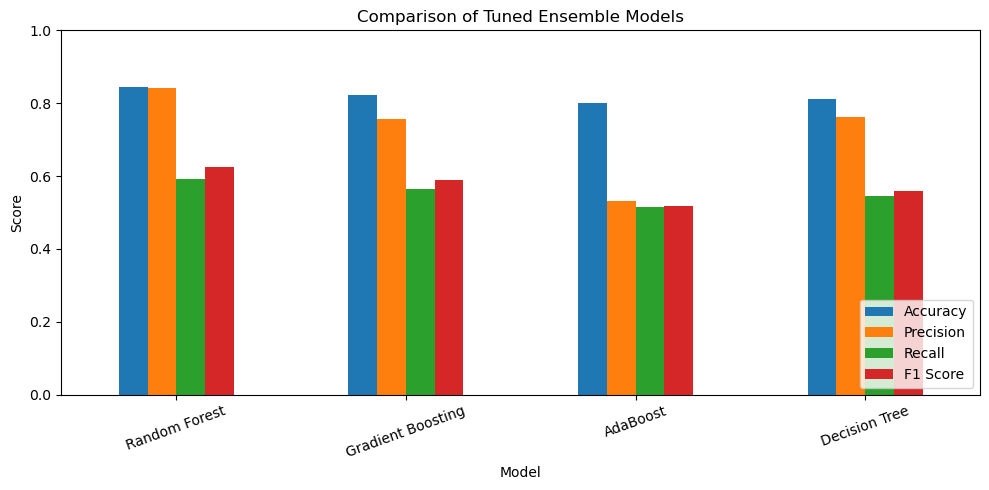

In [57]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Comparison of Tuned Ensemble Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Cross Validation

In [58]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Random Forest settings
random_forest_pipeline.set_params(
    classifier__n_estimators=50,
    classifier__n_jobs=1
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

start_time = time.time()

cv_scores = cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=2,
    error_score="raise"
)

print("Cross-validation F1 scores:", cv_scores)
print("Mean F1 Score:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())
print("Execution Time:", round(time.time() - start_time, 2), "seconds")

Cross-validation F1 scores: [0.57013052 0.58552833 0.57921662]
Mean F1 Score: 0.5782918238204311
Standard Deviation: 0.006320052603508162
Execution Time: 131.88 seconds


In [59]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import pandas as pd

cv_results = []

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for name, model in best_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Mean F1 Score": scores.mean(),
        "Std": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean F1 Score",
    ascending=False
).reset_index(drop=True)

print(cv_results_df)

               Model  Mean F1 Score       Std
0      Random Forest       0.594941  0.009446
1  Gradient Boosting       0.579175  0.007898
2      Decision Tree       0.550910  0.002715
3           AdaBoost       0.518158  0.001123


### compare  the algorithms

In [60]:
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)
best_model_name = results_df.loc[0, "Model"]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.loc[0, "F1 Score"])

best_model = best_models[best_model_name]

Best Model: Random Forest
Best F1 Score: 0.6245560446489898


### confusion matrix and classification report

Confusion Matrix:
[[ 6419  2183     2]
 [ 1344 13686     3]
 [   70   142    29]]


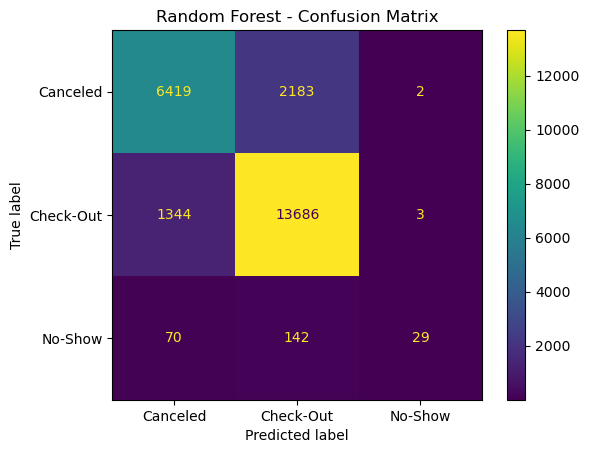

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.82      0.75      0.78      8604
   Check-Out       0.85      0.91      0.88     15033
     No-Show       0.85      0.12      0.21       241

    accuracy                           0.84     23878
   macro avg       0.84      0.59      0.62     23878
weighted avg       0.84      0.84      0.84     23878



In [62]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Predict test data
best_model = best_random_forest
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Random Forest - Confusion Matrix")
plt.show()

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

In [63]:
best_model_name = cv_results_df.loc[0, "Model"]

best_model = best_models[best_model_name]

print("Best Model:", best_model_name)
print("Best CV F1 Score:", cv_results_df.loc[0, "Mean F1 Score"])
print("Standard Deviation:", cv_results_df.loc[0, "Std"])

Best Model: Random Forest
Best CV F1 Score: 0.5949407704689599
Standard Deviation: 0.009446484903549318


In [64]:
y_probability = best_model.predict_proba(X_test)

print("Prediction Probabilities:")
print(y_probability[:10])

Prediction Probabilities:
[[3.37330986e-01 6.57118933e-01 5.55008134e-03]
 [1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [3.98070523e-02 9.42795029e-01 1.73979189e-02]
 [3.27760297e-01 6.67865223e-01 4.37448023e-03]
 [7.69680290e-01 2.12819782e-01 1.74999278e-02]
 [1.97809702e-01 7.98379536e-01 3.81076151e-03]
 [6.03735378e-02 9.37936977e-01 1.68948550e-03]
 [8.83058824e-01 1.16941176e-01 0.00000000e+00]
 [3.38495163e-01 6.60739071e-01 7.65766205e-04]]


In [67]:
print("Model classes:", best_model.classes_)
print("Target unique values:", y_train.unique())

Model classes: ['Canceled' 'Check-Out' 'No-Show']
Target unique values: ['Canceled' 'Check-Out' 'No-Show']


In [68]:
import pandas as pd

y_probability = best_model.predict_proba(X_test)

probability_df = pd.DataFrame(
    y_probability,
    columns=best_model.classes_
)

probability_df["Predicted Status"] = best_model.predict(X_test)

probability_df["Actual Status"] = y_test.values

print(probability_df.head(10))

   Canceled  Check-Out   No-Show Predicted Status Actual Status
0  0.337331   0.657119  0.005550        Check-Out     Check-Out
1  1.000000   0.000000  0.000000         Canceled      Canceled
2  1.000000   0.000000  0.000000         Canceled      Canceled
3  0.039807   0.942795  0.017398        Check-Out     Check-Out
4  0.327760   0.667865  0.004374        Check-Out     Check-Out
5  0.769680   0.212820  0.017500         Canceled      Canceled
6  0.197810   0.798380  0.003811        Check-Out     Check-Out
7  0.060374   0.937937  0.001689        Check-Out     Check-Out
8  0.883059   0.116941  0.000000         Canceled      Canceled
9  0.338495   0.660739  0.000766        Check-Out     Check-Out


### save the model

In [69]:
import joblib

joblib.dump(
    best_model,
    "hotel_reservation_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [70]:
best_model = joblib.load("hotel_reservation_model.pkl")
print("Model loaded successfully!")

Model loaded successfully!


### Test predictions on new booking data

In [71]:
new_booking = pd.DataFrame([{
    'hotel': 'City Hotel',
    'lead_time': 50,
    'arrival_date_year': 2017,
    'arrival_date_month': 'August',
    'arrival_date_week_number': 32,
    'arrival_date_day_of_month': 10,
    'stays_in_weekend_nights': 2,
    'stays_in_week_nights': 3,
    'adults': 2,
    'children': 0,
    'babies': 0,
    'meal': 'BB',
    'country': 'PRT',
    'market_segment': 'Online TA',
    'distribution_channel': 'TA/TO',
    'is_repeated_guest': 0,
    'previous_cancellations': 0,
    'previous_bookings_not_canceled': 0,
    'reserved_room_type': 'A',
    'deposit_type': 'No Deposit',
    'customer_type': 'Transient',
    'adr': 100.0,
    'required_car_parking_spaces': 0,
    'total_of_special_requests': 1,
    'city': 'Hyderabad'
}])

In [72]:
prediction = best_model.predict(new_booking)

print("Predicted Reservation Status:", prediction[0])

Predicted Reservation Status: Check-Out


In [73]:
probabilities = best_model.predict_proba(new_booking)[0]

for status, probability in zip(best_model.classes_, probabilities):
    print(f"{status}: {probability * 100:.2f}%")

Canceled: 36.59%
Check-Out: 60.73%
No-Show: 2.68%
